<a href="https://colab.research.google.com/github/Sparky1306/SalesVision-Sales-Forecasting/blob/main/SalesVision_%E2%80%94_Sales_Forecasting_%26_Revenue_Analytics.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [3]:
%pip install pandas numpy matplotlib seaborn statsmodels scikit-learn

In [5]:
import pandas as pd

df = pd.read_csv("train_india.csv")

display(df.head())

,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country,City,State,Postal Code,Region,Product ID,Category,Sub-Category,Product Name,Sales
0,1,IN-2025-152156,08/11/2025,11/11/2025,Second Class,GM-12520,Geeta Menon,Consumer,India,Visakhapatnam,Andhra Pradesh,530021.0,South,FUR-BO-10001798,Furniture,Bookcases,Bush Somerset Collection Bookcase,22266.60
1,2,IN-2025-152156,08/11/2025,11/11/2025,Second Class,GM-12520,Geeta Menon,Consumer,India,Visakhapatnam,Andhra Pradesh,530021.0,South,FUR-CH-10000454,Furniture,Chairs,"Hon Deluxe Fabric Upholstered Stacking Chairs,...",62214.90
2,3,IN-2025-138688,12/06/2025,16/06/2025,Second Class,NH-13045,Naveen Hazarika,Corporate,India,Mumbai,Maharashtra,400037.0,West,OFF-LA-10000240,Office Supplies,Labels,Self-Adhesive Address Labels for Typewriters b...,1242.70
3,4,IN-2024-108966,11/10/2024,18/10/2024,Standard Class,NT-20335,Nazia Thomas,Consumer,India,Belagavi,Karnataka,590012.0,South,FUR-TA-10000577,Furniture,Tables,Bretford CR4500 Series Slim Rectangular Table,81394.09
4,5,IN-2024-108966,11/10/2024,18/10/2024,Standard Class,NT-20335,Nazia Thomas,Consumer,India,Belagavi,Karnataka,590012.0,South,OFF-ST-10000760,Office Supplies,Storage,Eldon Fold 'N Roll Cart System,1901.28


In [6]:
from pathlib import Path
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.metrics import mean_absolute_error, mean_squared_error
from statsmodels.tsa.holtwinters import ExponentialSmoothing

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.figsize"] = (12, 5)

DATA_PATH = Path("train_india.csv")
df = pd.read_csv(DATA_PATH)

print(f"Rows: {df.shape[0]:,}")
print(f"Columns: {df.shape[1]}")
display(df.head())

Rows: 8,591
Columns: 18


,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country,City,State,Postal Code,Region,Product ID,Category,Sub-Category,Product Name,Sales
0,1,IN-2025-152156,08/11/2025,11/11/2025,Second Class,GM-12520,Geeta Menon,Consumer,India,Visakhapatnam,Andhra Pradesh,530021.0,South,FUR-BO-10001798,Furniture,Bookcases,Bush Somerset Collection Bookcase,22266.60
1,2,IN-2025-152156,08/11/2025,11/11/2025,Second Class,GM-12520,Geeta Menon,Consumer,India,Visakhapatnam,Andhra Pradesh,530021.0,South,FUR-CH-10000454,Furniture,Chairs,"Hon Deluxe Fabric Upholstered Stacking Chairs,...",62214.90
2,3,IN-2025-138688,12/06/2025,16/06/2025,Second Class,NH-13045,Naveen Hazarika,Corporate,India,Mumbai,Maharashtra,400037.0,West,OFF-LA-10000240,Office Supplies,Labels,Self-Adhesive Address Labels for Typewriters b...,1242.70
3,4,IN-2024-108966,11/10/2024,18/10/2024,Standard Class,NT-20335,Nazia Thomas,Consumer,India,Belagavi,Karnataka,590012.0,South,FUR-TA-10000577,Furniture,Tables,Bretford CR4500 Series Slim Rectangular Table,81394.09
4,5,IN-2024-108966,11/10/2024,18/10/2024,Standard Class,NT-20335,Nazia Thomas,Consumer,India,Belagavi,Karnataka,590012.0,South,OFF-ST-10000760,Office Supplies,Storage,Eldon Fold 'N Roll Cart System,1901.28


In [8]:
print("Column names:")
print(df.columns.tolist())

print("\nData types and non-null counts:")
df.info()

print("\nMissing values (largest first):")
display(df.isna().sum().sort_values(ascending=False).to_frame("missing_count"))

print("\nDuplicate rows:", df.duplicated().sum())
print("\nSales summary:")
display(df["Sales"].describe().to_frame())

Column names:
['Row ID', 'Order ID', 'Order Date', 'Ship Date', 'Ship Mode', 'Customer ID', 'Customer Name', 'Segment', 'Country', 'City', 'State', 'Postal Code', 'Region', 'Product ID', 'Category', 'Sub-Category', 'Product Name', 'Sales']

Data types and non-null counts:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8591 entries, 0 to 8590
Data columns (total 18 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Row ID         8591 non-null   int64  
 1   Order ID       8591 non-null   object 
 2   Order Date     8591 non-null   object 
 3   Ship Date      8591 non-null   object 
 4   Ship Mode      8591 non-null   object 
 5   Customer ID    8591 non-null   object 
 6   Customer Name  8591 non-null   object 
 7   Segment        8591 non-null   object 
 8   Country        8591 non-null   object 
 9   City           8591 non-null   object 
 10  State          8591 non-null   object 
 11  Postal Code    8581 non-null   float64
 12 

,missing_count
Postal Code,10
Row ID,0
Order ID,0
Order Date,0
Ship Mode,0
Ship Date,0
Customer Name,0
Segment,0
Country,0
Customer ID,0



Duplicate rows: 0

Sales summary:


,Sales
count,8.591000e+03
mean,1.962114e+04
std,5.303488e+04
min,3.774000e+01
25%,1.462000e+03
50%,4.666500e+03
75%,1.801660e+04
max,1.924271e+06


In [12]:
# Check missing values in the important columns
print("Missing order dates:", df["Order Date"].isna().sum())
print("Missing sales values:", df["Sales"].isna().sum())

# Check duplicate rows
print("Duplicate rows:", df.duplicated().sum())

# Check sales values
print("Negative sales:", (df["Sales"] < 0).sum())

# Display column data types
display(df.dtypes.to_frame("Data Type"))

Missing order dates: 0
Missing sales values: 0
Duplicate rows: 0
Negative sales: 0


,Data Type
Row ID,int64
Order ID,object
Order Date,datetime64[ns]
Ship Date,object
Ship Mode,object
Customer ID,object
Customer Name,object
Segment,object
Country,object
City,object


In [13]:
import pandas as pd
import numpy as np

# Convert dates into proper datetime format
df["Order Date"] = pd.to_datetime(
    df["Order Date"],
    dayfirst=True,
    errors="coerce"
)

df["Ship Date"] = pd.to_datetime(
    df["Ship Date"],
    dayfirst=True,
    errors="coerce"
)

# Ensure Sales is numeric
df["Sales"] = pd.to_numeric(df["Sales"], errors="coerce")

# Keep rows with valid order dates and sales amounts
sales_df = df.dropna(
    subset=["Order Date", "Sales"]
).copy()

# Check the cleaned dataset
print("Original rows:", len(df))
print("Cleaned rows:", len(sales_df))
print("First order date:", sales_df["Order Date"].min())
print("Last order date:", sales_df["Order Date"].max())

display(sales_df.head())

Original rows: 8591
Cleaned rows: 8591
First order date: 2023-01-03 00:00:00
Last order date: 2026-09-30 00:00:00


,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country,City,State,Postal Code,Region,Product ID,Category,Sub-Category,Product Name,Sales
0,1,IN-2025-152156,2025-11-08,2025-11-11,Second Class,GM-12520,Geeta Menon,Consumer,India,Visakhapatnam,Andhra Pradesh,530021.0,South,FUR-BO-10001798,Furniture,Bookcases,Bush Somerset Collection Bookcase,22266.60
1,2,IN-2025-152156,2025-11-08,2025-11-11,Second Class,GM-12520,Geeta Menon,Consumer,India,Visakhapatnam,Andhra Pradesh,530021.0,South,FUR-CH-10000454,Furniture,Chairs,"Hon Deluxe Fabric Upholstered Stacking Chairs,...",62214.90
2,3,IN-2025-138688,2025-06-12,2025-06-16,Second Class,NH-13045,Naveen Hazarika,Corporate,India,Mumbai,Maharashtra,400037.0,West,OFF-LA-10000240,Office Supplies,Labels,Self-Adhesive Address Labels for Typewriters b...,1242.70
3,4,IN-2024-108966,2024-10-11,2024-10-18,Standard Class,NT-20335,Nazia Thomas,Consumer,India,Belagavi,Karnataka,590012.0,South,FUR-TA-10000577,Furniture,Tables,Bretford CR4500 Series Slim Rectangular Table,81394.09
4,5,IN-2024-108966,2024-10-11,2024-10-18,Standard Class,NT-20335,Nazia Thomas,Consumer,India,Belagavi,Karnataka,590012.0,South,OFF-ST-10000760,Office Supplies,Storage,Eldon Fold 'N Roll Cart System,1901.28


In [14]:
# Group individual orders into monthly revenue
monthly_sales = (
    sales_df
    .set_index("Order Date")["Sales"]
    .resample("MS")
    .sum()
)

# Make sure each month is represented
monthly_sales = monthly_sales.asfreq("MS", fill_value=0)

# Convert to a DataFrame for easy viewing
monthly_sales_df = monthly_sales.reset_index()
monthly_sales_df.columns = ["Month", "Total Sales"]

print("Number of months:", len(monthly_sales_df))
print("Total revenue:", round(monthly_sales.sum(), 2))
print("Average monthly revenue:", round(monthly_sales.mean(), 2))

display(monthly_sales_df.head(12))

Number of months: 45
Total revenue: 168565209.13
Average monthly revenue: 3745893.54


,Month,Total Sales
0,2023-01-01,1207485.10
1,2023-02-01,384190.82
2,2023-03-01,4692492.73
3,2023-04-01,2372082.68
4,2023-05-01,2009765.75
5,2023-06-01,2917449.53
6,2023-07-01,2871431.15
7,2023-08-01,2304990.60
8,2023-09-01,6937999.78
9,2023-10-01,2673538.41


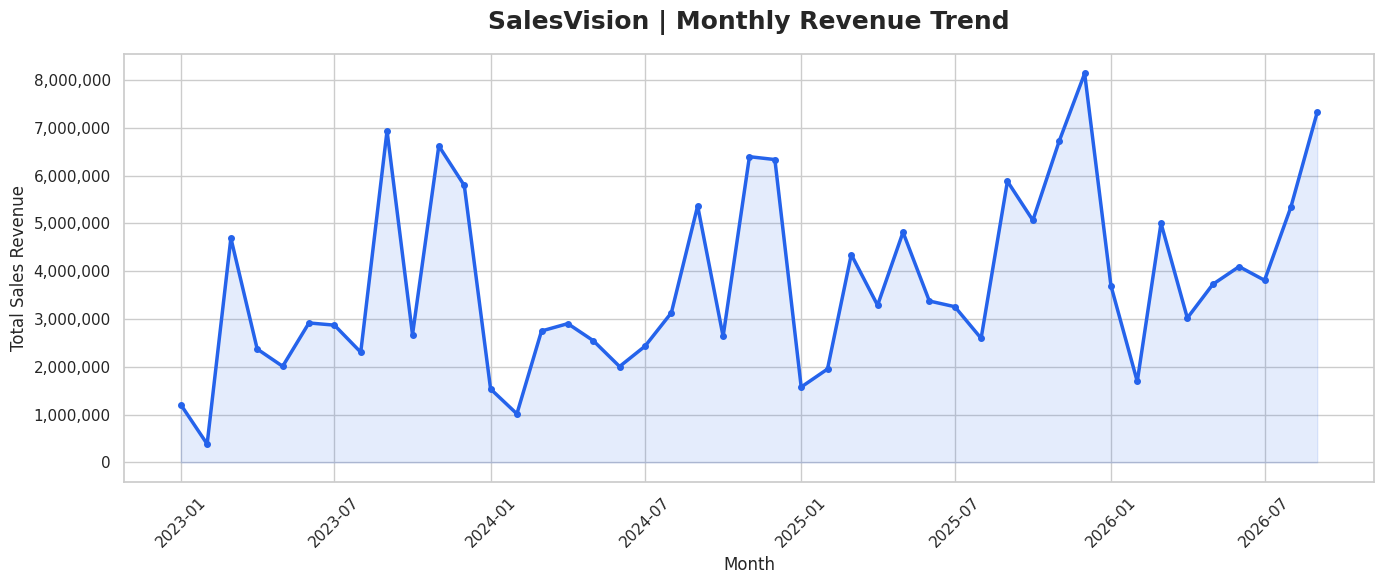

In [15]:
import matplotlib.pyplot as plt
import seaborn as sns
import matplotlib.ticker as mtick

sns.set_theme(style="whitegrid")

fig, ax = plt.subplots(figsize=(14, 6))

ax.plot(
    monthly_sales.index,
    monthly_sales.values,
    color="#2563EB",
    linewidth=2.5,
    marker="o",
    markersize=4
)

ax.fill_between(
    monthly_sales.index,
    monthly_sales.values,
    alpha=0.12,
    color="#2563EB"
)

ax.set_title(
    "SalesVision | Monthly Revenue Trend",
    fontsize=18,
    fontweight="bold",
    pad=18
)
ax.set_xlabel("Month", fontsize=12)
ax.set_ylabel("Total Sales Revenue", fontsize=12)
ax.yaxis.set_major_formatter(
    mtick.FuncFormatter(lambda x, _: f"{x:,.0f}")
)

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

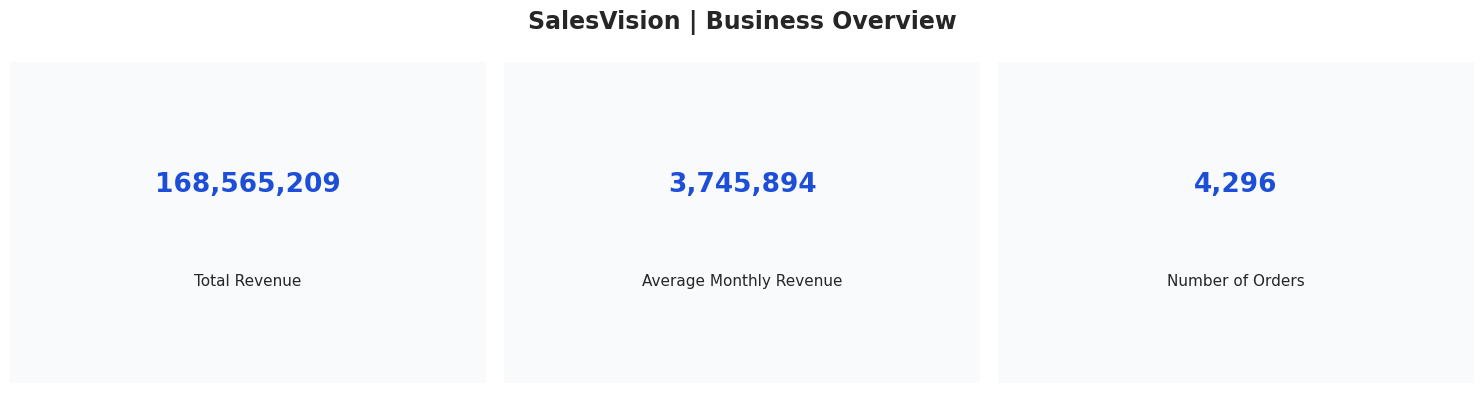

Highest revenue month: December 2025
Highest monthly revenue: 8,137,825.27
Lowest revenue month: February 2023
Lowest monthly revenue: 384,190.82


In [16]:
total_revenue = sales_df["Sales"].sum()
average_monthly_revenue = monthly_sales.mean()
highest_month = monthly_sales.idxmax()
lowest_month = monthly_sales.idxmin()

fig, axes = plt.subplots(1, 3, figsize=(15, 4))

kpis = [
    ("Total Revenue", f"{total_revenue:,.0f}"),
    ("Average Monthly Revenue", f"{average_monthly_revenue:,.0f}"),
    ("Number of Orders", f"{sales_df['Order ID'].nunique():,}")
]

for ax, (title, value) in zip(axes, kpis):
    ax.set_facecolor("#F8FAFC")
    ax.text(
        0.5, 0.62, value,
        ha="center", va="center",
        fontsize=19, fontweight="bold",
        color="#1D4ED8",
        transform=ax.transAxes
    )
    ax.text(
        0.5, 0.32, title,
        ha="center", va="center",
        fontsize=11,
        transform=ax.transAxes
    )
    ax.set_xticks([])
    ax.set_yticks([])
    for spine in ax.spines.values():
        spine.set_visible(False)

fig.suptitle(
    "SalesVision | Business Overview",
    fontsize=17,
    fontweight="bold"
)
plt.tight_layout()
plt.show()

print("Highest revenue month:", highest_month.strftime("%B %Y"))
print("Highest monthly revenue:", f"{monthly_sales.max():,.2f}")
print("Lowest revenue month:", lowest_month.strftime("%B %Y"))
print("Lowest monthly revenue:", f"{monthly_sales.min():,.2f}")

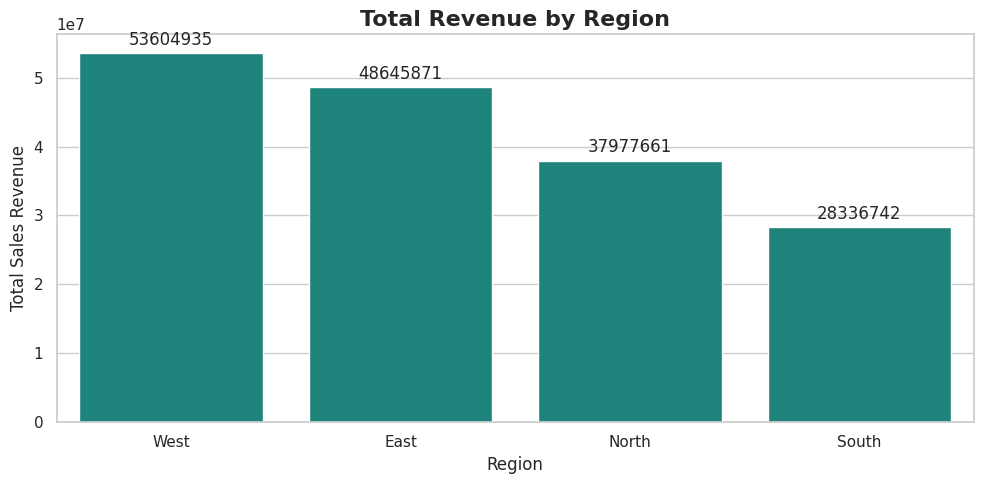

,Total Sales
Region,
West,53604934.66
East,48645870.73
North,37977661.38
South,28336742.36


In [17]:
region_sales = (
    sales_df.groupby("Region")["Sales"]
    .sum()
    .sort_values(ascending=False)
)

plt.figure(figsize=(10, 5))

ax = sns.barplot(
    x=region_sales.index,
    y=region_sales.values,
    color="#0D9488"
)

ax.set_title(
    "Total Revenue by Region",
    fontsize=16,
    fontweight="bold"
)
ax.set_xlabel("Region")
ax.set_ylabel("Total Sales Revenue")

for container in ax.containers:
    ax.bar_label(container, fmt="%.0f", padding=3)

plt.tight_layout()
plt.show()

display(region_sales.to_frame("Total Sales"))

In [18]:
HORIZON = 6

train = monthly_sales.iloc[:-HORIZON]
test = monthly_sales.iloc[-HORIZON:]

print("Training period:", train.index.min(), "to", train.index.max())
print("Testing period:", test.index.min(), "to", test.index.max())

print("\nTraining months:", len(train))
print("Testing months:", len(test))

display(test.to_frame("Actual Sales"))

Training period: 2023-01-01 00:00:00 to 2026-03-01 00:00:00
Testing period: 2026-04-01 00:00:00 to 2026-09-01 00:00:00

Training months: 39
Testing months: 6


,Actual Sales
Order Date,
2026-04-01,3021062.34
2026-05-01,3725208.48
2026-06-01,4096211.85
2026-07-01,3810133.84
2026-08-01,5341217.08
2026-09-01,7322995.50


In [20]:
from statsmodels.tsa.holtwinters import ExponentialSmoothing
from sklearn.metrics import mean_absolute_error, mean_squared_error

# Model 1: Naive forecast
naive_pred = pd.Series(
    train.iloc[-1],
    index=test.index,
    name="Naive"
)

# Model 2: Seasonal naive forecast
seasonal_pred = pd.Series(
    train.iloc[-12:-6].to_numpy(),
    index=test.index,
    name="Seasonal Naive"
)

# Model 3: Holt-Winters
hw_model = ExponentialSmoothing(
    train,
    trend="add",
    seasonal="add",
    seasonal_periods=12,
    initialization_method="estimated"
).fit(optimized=True)

hw_pred = hw_model.forecast(HORIZON).clip(lower=0)
hw_pred.index = test.index
hw_pred.name = "Holt-Winters"

# Evaluate every model on the same six months
predictions = {
    "Naive": naive_pred,
    "Seasonal Naive": seasonal_pred,
    "Holt-Winters": hw_pred
}

results = []

for model_name, prediction in predictions.items():
    results.append({
        "Model": model_name,
        "MAE": mean_absolute_error(test, prediction),
        "RMSE": np.sqrt(mean_squared_error(test, prediction))
    })

metrics = (
    pd.DataFrame(results)
    .sort_values("RMSE")
    .reset_index(drop=True)
)

display(metrics.round(2))

best_model_name = metrics.iloc[0]["Model"]
print("Best model based on holdout RMSE:", best_model_name)

,Model,MAE,RMSE
0,Holt-Winters,736870.59,831896.52
1,Seasonal Naive,1136088.62,1396302.62
2,Naive,1336396.04,1489121.70


Best model based on holdout RMSE: Holt-Winters


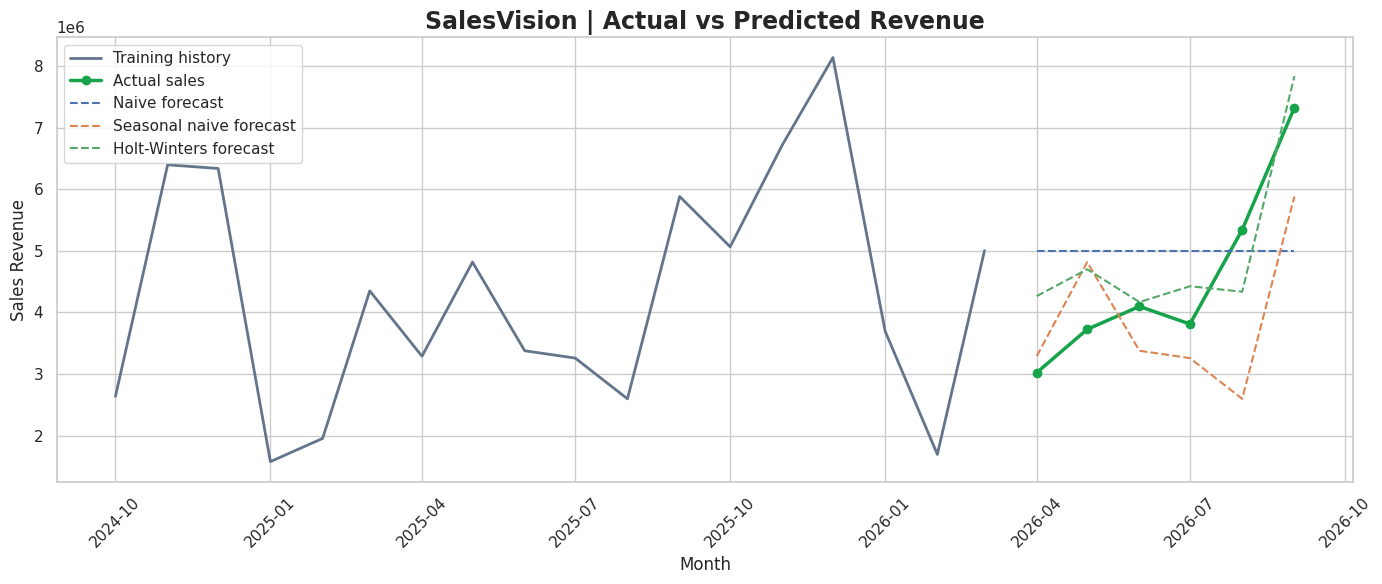

In [21]:
plt.figure(figsize=(14, 6))

plt.plot(
    train.tail(18),
    label="Training history",
    color="#64748B",
    linewidth=2
)

plt.plot(
    test,
    label="Actual sales",
    color="#16A34A",
    marker="o",
    linewidth=2.5
)

plt.plot(
    naive_pred,
    label="Naive forecast",
    linestyle="--"
)

plt.plot(
    seasonal_pred,
    label="Seasonal naive forecast",
    linestyle="--"
)

plt.plot(
    hw_pred,
    label="Holt-Winters forecast",
    linestyle="--"
)

plt.title(
    "SalesVision | Actual vs Predicted Revenue",
    fontsize=17,
    fontweight="bold"
)
plt.xlabel("Month")
plt.ylabel("Sales Revenue")
plt.legend()
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [22]:
future_dates = pd.date_range(
    start=monthly_sales.index[-1] + pd.offsets.MonthBegin(1),
    periods=6,
    freq="MS"
)

if best_model_name == "Naive":
    future_predictions = np.repeat(
        monthly_sales.iloc[-1], 6
    )

elif best_model_name == "Seasonal Naive":
    future_predictions = monthly_sales.iloc[-12:-6].to_numpy()

else:
    final_model = ExponentialSmoothing(
        monthly_sales,
        trend="add",
        seasonal="add",
        seasonal_periods=12,
        initialization_method="estimated"
    ).fit(optimized=True)

    future_predictions = (
        final_model.forecast(6)
        .clip(lower=0)
        .to_numpy()
    )

forecast_df = pd.DataFrame({
    "Month": future_dates,
    "Forecast Sales": future_predictions
})

display(
    forecast_df.style.format({
        "Forecast Sales": "{:,.2f}"
    })
)

,Month,Forecast Sales
0,2026-10-01 00:00:00,"4,086,208.78"
1,2026-11-01 00:00:00,"7,872,794.42"
2,2026-12-01 00:00:00,"7,421,808.64"
3,2027-01-01 00:00:00,"2,920,951.01"
4,2027-02-01 00:00:00,"2,839,963.70"
5,2027-03-01 00:00:00,"5,002,930.75"


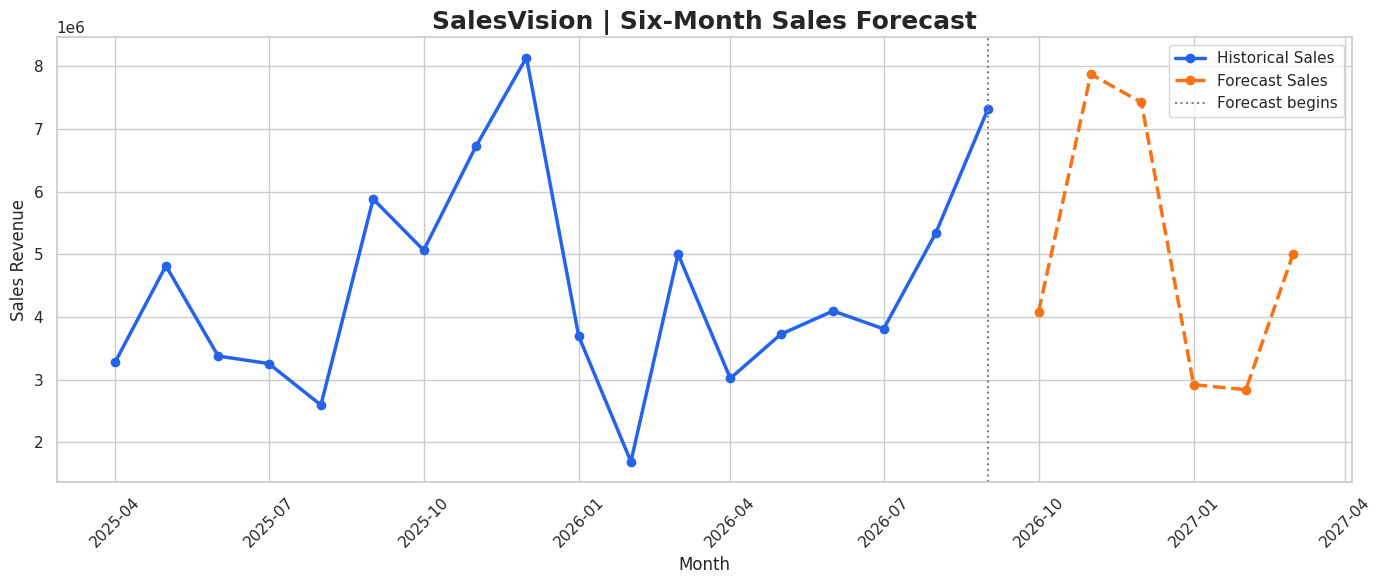

In [23]:
fig, ax = plt.subplots(figsize=(14, 6))

ax.plot(
    monthly_sales.tail(18),
    label="Historical Sales",
    color="#2563EB",
    marker="o",
    linewidth=2.5
)

ax.plot(
    forecast_df.set_index("Month")["Forecast Sales"],
    label="Forecast Sales",
    color="#F97316",
    marker="o",
    linestyle="--",
    linewidth=2.5
)

ax.axvline(
    monthly_sales.index[-1],
    color="gray",
    linestyle=":",
    label="Forecast begins"
)

ax.set_title(
    "SalesVision | Six-Month Sales Forecast",
    fontsize=18,
    fontweight="bold"
)
ax.set_xlabel("Month")
ax.set_ylabel("Sales Revenue")
ax.legend()
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()